# EXP06 — Ảnh hưởng của Learning Rate

So sánh baseline CNN được huấn luyện bằng Adam ở ba learning rate. Giữ nguyên dữ liệu, split, seed, batch size, số epoch và kiến trúc để cô lập ảnh hưởng của learning rate.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

cwd = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (cwd, cwd.parent, cwd / "BTL02") if (p / "train.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục BTL02 hoặc BTL02/notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from evaluate import evaluate_checkpoint
from train import run_experiment, select_device

CONFIGS = {
    "Adam lr=0.0003": PROJECT_ROOT / "configs/exp06_lr_0003.yaml",
    "Adam lr=0.001": PROJECT_ROOT / "configs/exp06_lr_001.yaml",
    "Adam lr=0.003": PROJECT_ROOT / "configs/exp06_lr_003.yaml",
}
configs = {
    name: yaml.safe_load(path.read_text(encoding="utf-8"))
    for name, path in CONFIGS.items()
}
display(pd.DataFrame(configs).T)

,experiment,model,data_dir,output_dir,result_group,tensorboard_dir,epochs,batch_size,learning_rate,seed,device
Adam lr=0.0003,EXP006_Learning_Rate,baseline,data,results,EXP06/lr_0003,runs,30,64,0.0003,42,cuda
Adam lr=0.001,EXP006_Learning_Rate,baseline,data,results,EXP06/lr_001,runs,30,64,0.001,42,cuda
Adam lr=0.003,EXP006_Learning_Rate,baseline,data,results,EXP06/lr_003,runs,30,64,0.003,42,cuda


## Kiểm soát biến số

Ba lượt dùng chung baseline CNN, split 80/20, seed 42, batch size 64, Adam, 30 epoch và GPU CUDA. Learning rate là biến độc lập duy nhất.

In [2]:
varied_key = "learning_rate"
reference = next(iter(configs.values()))
shared_keys = ("model", "data_dir", "epochs", "batch_size", "seed", "device")
learning_rates = set()
for name, config in configs.items():
    for key in shared_keys:
        if config[key] != reference[key]:
            raise ValueError(f"{name} khác biến kiểm soát {key!r}.")
    if config.get("augmentation"):
        raise ValueError(f"{name} phải tắt augmentation.")
    learning_rates.add(config[varied_key])
if len(learning_rates) != len(configs):
    raise ValueError("Mỗi lượt phải có learning rate riêng.")
if reference["model"] != "baseline" or reference["device"] != "cuda":
    raise ValueError("EXP06 yêu cầu baseline CNN và device=cuda.")
print("Các biến kiểm soát khớp nhau; learning rate là biến duy nhất được thay đổi.")

Các biến kiểm soát khớp nhau; learning rate là biến duy nhất được thay đổi.


## Huấn luyện hoặc nạp run đã có

Giữ `None` để huấn luyện cấu hình tương ứng. Sau khi hoàn tất, notebook tự ghi các đường dẫn run bên dưới để các lần chạy sau có thể tái sử dụng checkpoint.

In [3]:
RUN_DIRS = {
    "Adam lr=0.0003": None,
    "Adam lr=0.001": None,
    "Adam lr=0.003": None,
}
runs = {}
for name, config_path in CONFIGS.items():
    run_path = RUN_DIRS[name]
    if run_path is None:
        run = run_experiment(config_path)
    else:
        run_path = Path(run_path)
        run = run_path if run_path.is_absolute() else PROJECT_ROOT / run_path
        if not (run / "best.pth").is_file():
            raise FileNotFoundError(f"Không tìm thấy checkpoint: {run / 'best.pth'}")
    runs[name] = run
    print(f"{name}: {run.relative_to(PROJECT_ROOT)}")

D:\DeepLearning_Group\BTL02\results\EXP06\lr_0003\baseline\20261127_103054_200157 cuda {'input': [64, 1, 48, 48], 'output': [64, 7], 'loss': 1.9359233379364014, 'finite_gradients': True}
01/30  train 1.7682 26.91%  val 1.6837 33.96%
02/30  train 1.6019 38.20%  val 1.5432 40.06%
03/30  train 1.4944 42.90%  val 1.4519 44.36%
04/30  train 1.4238 45.24%  val 1.4164 46.38%
05/30  train 1.3643 48.05%  val 1.3517 48.21%
06/30  train 1.3068 50.26%  val 1.3127 49.70%
07/30  train 1.2629 52.24%  val 1.2830 51.39%
08/30  train 1.2150 53.90%  val 1.2532 52.44%
09/30  train 1.1706 56.21%  val 1.2403 53.36%
10/30  train 1.1345 57.32%  val 1.2313 53.66%
11/30  train 1.0907 59.65%  val 1.2314 53.73%
12/30  train 1.0479 61.34%  val 1.2151 54.32%
13/30  train 1.0077 62.75%  val 1.2174 55.71%
14/30  train 0.9670 64.59%  val 1.2236 54.70%
15/30  train 0.9247 66.13%  val 1.2470 55.22%
16/30  train 0.8911 67.63%  val 1.2359 55.80%
17/30  train 0.8409 69.64%  val 1.2209 56.51%
18/30  train 0.7989 71.08%  val

## Đánh giá trên validation

Mỗi checkpoint tốt nhất theo validation loss được đánh giá trên cùng validation split. Các chỉ số bên dưới là validation, không phải test.

In [4]:
evaluations = {}
rows = []
for name, run in runs.items():
    config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
    training = json.loads((run / "training.json").read_text(encoding="utf-8"))
    saved = None
    evaluation_path = run / "evaluation.json"
    if evaluation_path.is_file():
        candidate = json.loads(evaluation_path.read_text(encoding="utf-8"))
        if candidate.get("split") == "validation":
            saved = candidate
    if saved is None:
        saved = evaluate_checkpoint(
            run,
            PROJECT_ROOT / config["data_dir"],
            config["batch_size"],
            select_device(config["device"]),
            split="validation",
        )
    evaluations[name] = saved
    rows.append({
        "Learning rate": config["learning_rate"],
        "Best epoch": training["best_epoch"],
        "Best validation loss": training["best_val_loss"],
        "Validation accuracy": saved["accuracy"],
        "Validation macro F1": saved["macro_f1"],
        "Thời gian train (giây)": training["training_seconds"],
    })
results = pd.DataFrame(rows, index=list(runs)).sort_values("Learning rate")
display(results.round(4))

Validation accuracy 54.32% | Macro F1 0.4721
Validation accuracy 54.60% | Macro F1 0.4823
Validation accuracy 50.38% | Macro F1 0.4444


,Learning rate,Best epoch,Best validation loss,Validation accuracy,Validation macro F1,Thời gian train (giây)
Adam lr=0.0003,0.0003,12,1.2151,0.5432,0.4721,93.0900
Adam lr=0.001,0.0010,7,1.2076,0.5460,0.4823,93.6153
Adam lr=0.003,0.0030,7,1.3130,0.5038,0.4444,93.4674


## Learning curves

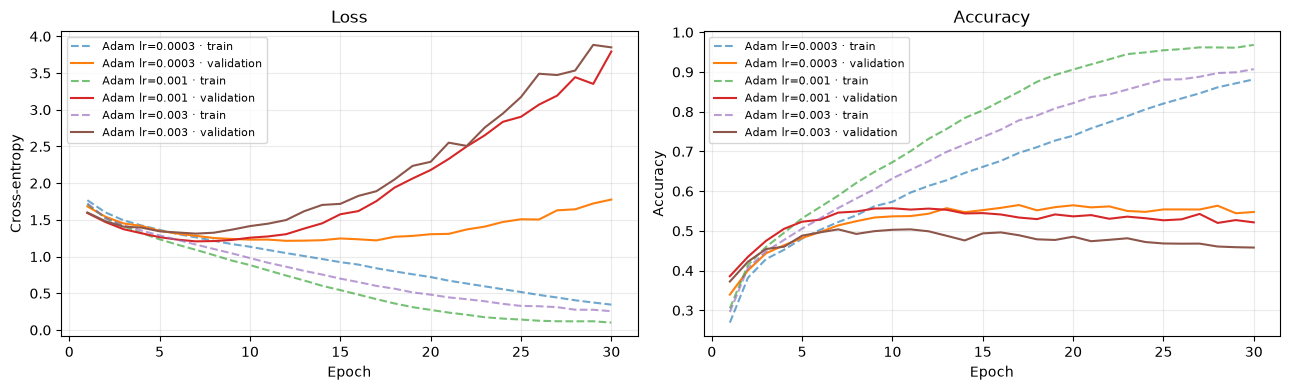

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, run in runs.items():
    history = pd.read_csv(run / "history.csv")
    axes[0].plot(history["epoch"], history["train_loss"], linestyle="--", alpha=0.65, label=f"{name} · train")
    axes[0].plot(history["epoch"], history["val_loss"], label=f"{name} · validation")
    axes[1].plot(history["epoch"], history["train_accuracy"], linestyle="--", alpha=0.65, label=f"{name} · train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label=f"{name} · validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Macro/per-class F1, confusion matrix và filter

,Adam lr=0.0003,Adam lr=0.001,Adam lr=0.003
Angry,0.4405,0.4028,0.3719
Disgust,0.1600,0.2909,0.2647
Fear,0.3235,0.3200,0.2917
Happy,0.7567,0.7481,0.7011
Sad,0.4574,0.4203,0.3734
Surprise,0.6877,0.6657,0.6378
Neutral,0.4785,0.5284,0.4698


### Adam lr=0.0003

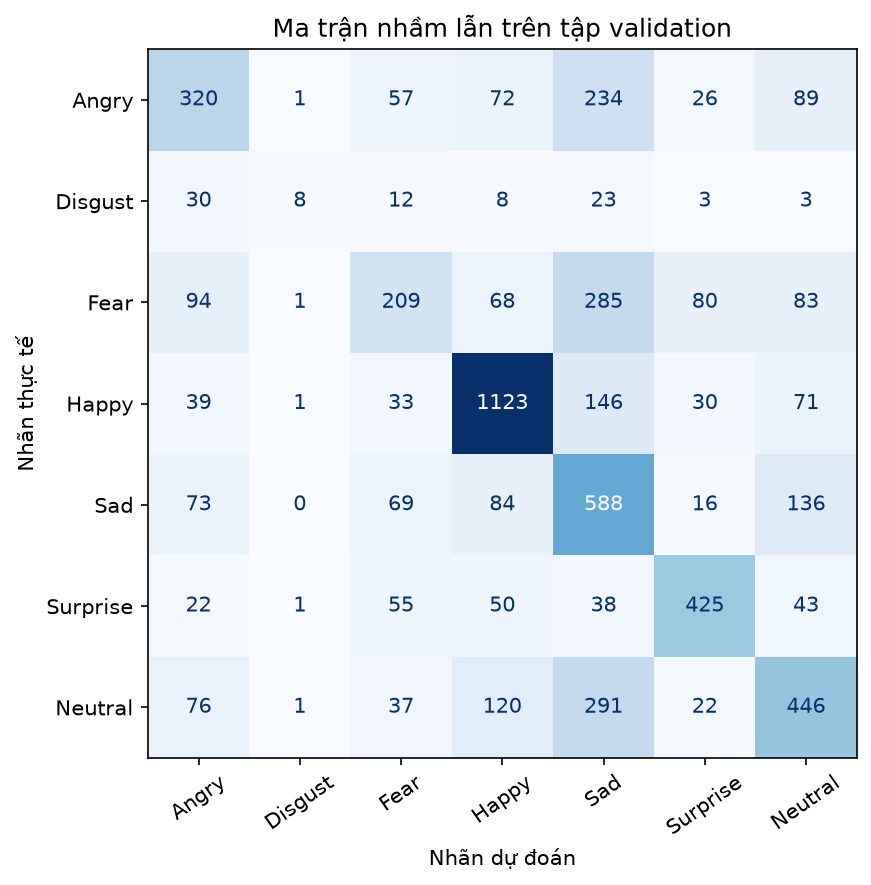

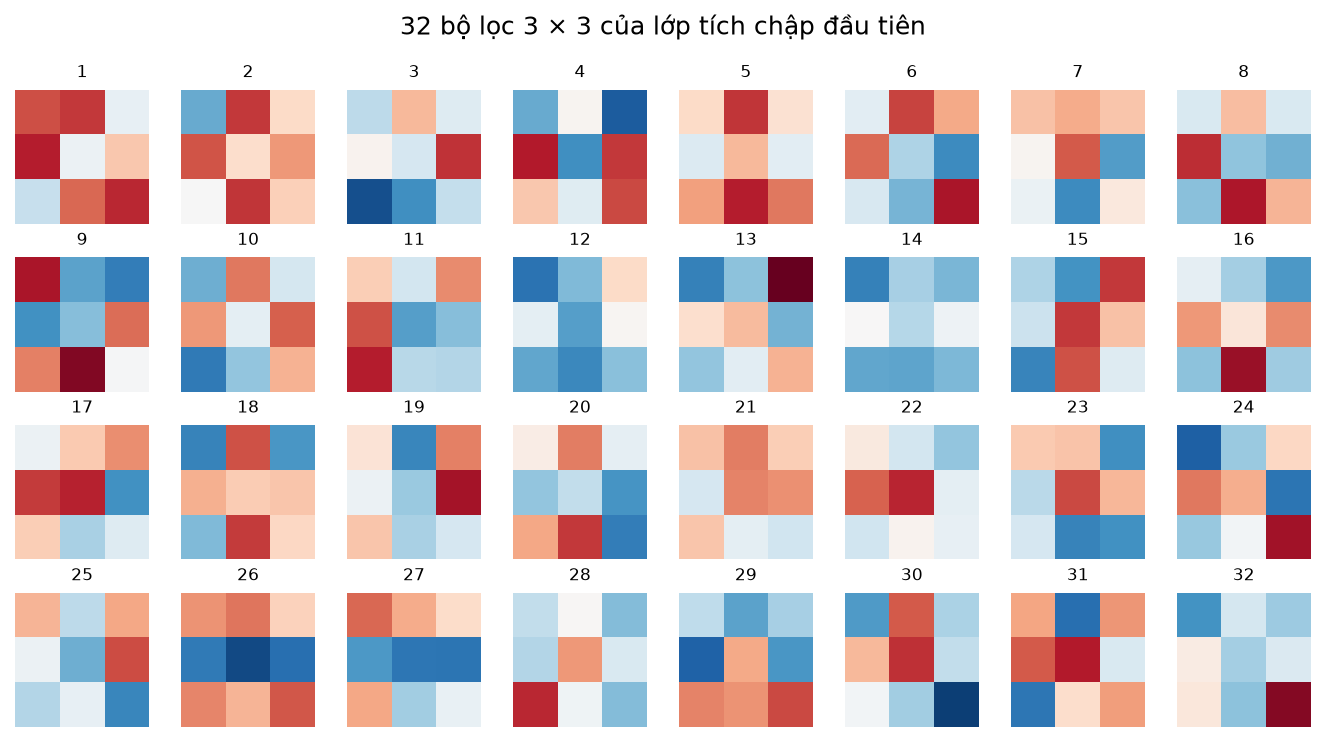

### Adam lr=0.001

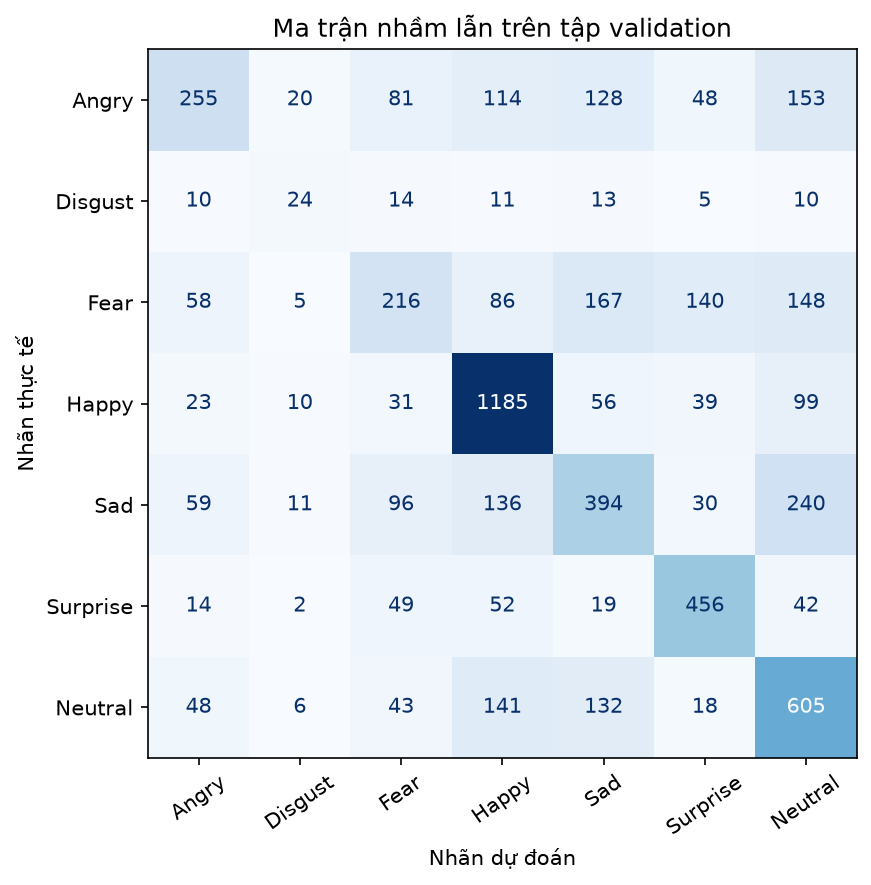

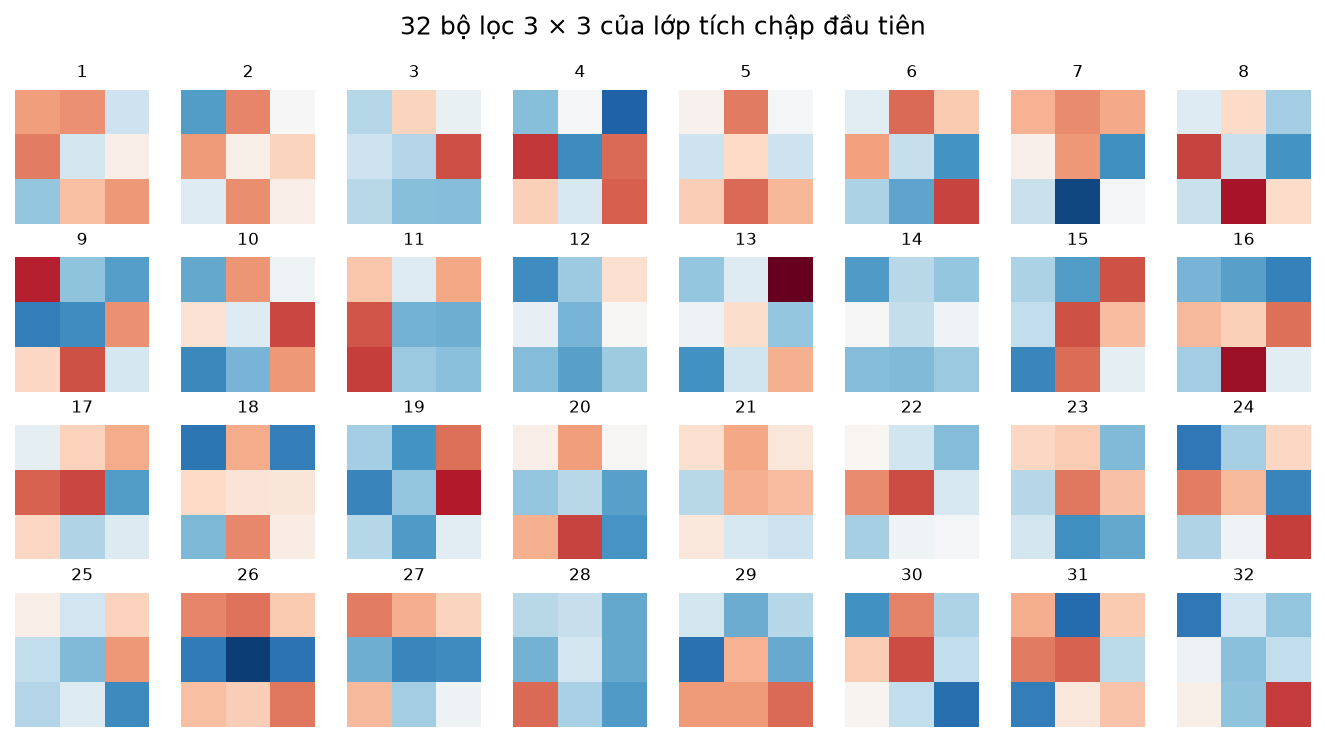

### Adam lr=0.003

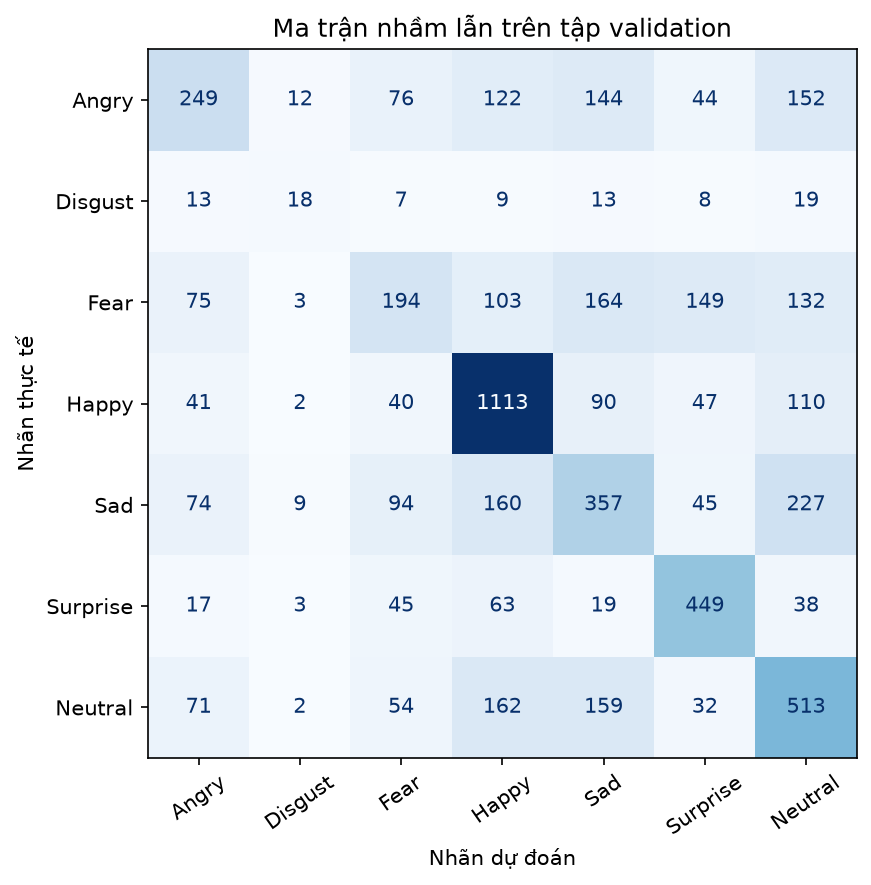

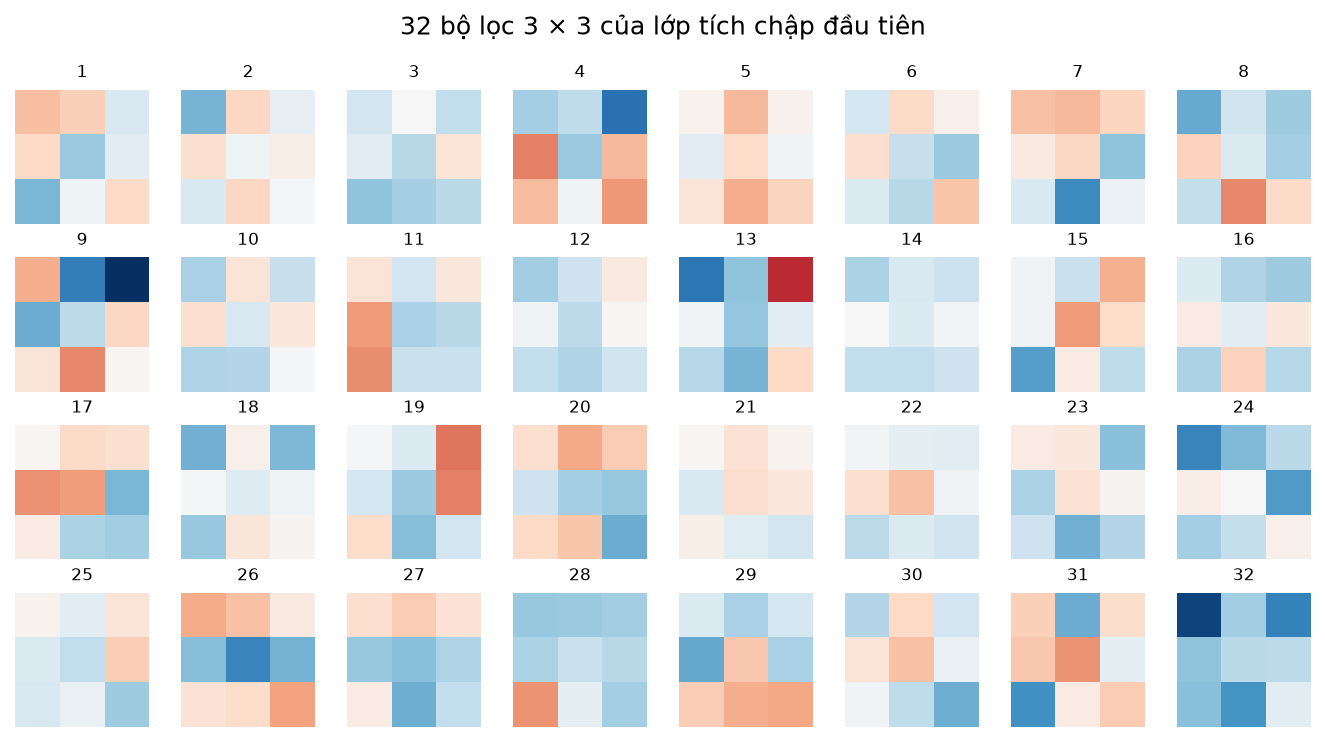

In [6]:
class_f1 = pd.DataFrame({
    name: {emotion: values["f1-score"] for emotion, values in result["per_class"].items()}
    for name, result in evaluations.items()
})
display(class_f1.round(4))
for name, run in runs.items():
    display(Markdown(f"### {name}"))
    display(Image(filename=str(run / "confusion_matrix.png"), width=650))
    display(Image(filename=str(run / "conv1_filters.png"), width=650))

## Nhận xét

So sánh validation loss, accuracy, macro F1, F1 từng lớp và learning curves. Learning rate nhỏ có thể hội tụ chậm; learning rate lớn có thể dao động hoặc làm validation kém ổn định. Chọn giá trị dựa trên validation, lưu ý kết quả là một lần chạy với seed cố định; chưa dùng test để chọn siêu tham số.